# Tugas - Medical Cost Prediction

| Nama | NRP |
|------|-----|
| Intifada Afkar lazain Muhammad | 5054251029|

## Deskripsi Tugas

Pada tugas ini, kita akan menggunakan Medical Cost Personal Dataset dari Kaggle.

Dataset:
- https://www.kaggle.com/mirichoi0218/insurance

Target yang diprediksi adalah `charges`.

Model yang digunakan:
1. Linear Regression
2. Polynomial Regression
3. Ridge Regression
4. Lasso Regression
5. Decision Tree Regressor
6. Support Vector Regression


# 1. Persiapan Dataset dan Eksplorasi Awal

In [177]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [178]:
# Load dataset.
df = pd.read_csv('/content/insurance.csv')

In [179]:
# Tampilkan beberapa baris pertama dataset.
display(df.head())

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [180]:
# Tampilkan informasi dataset.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [181]:
# Periksa missing value.
display(df.isnull().sum())

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [182]:
# Tampilkan statistik deskriptif fitur numerik.
display(df.describe())

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [183]:
# Tampilkan jumlah nilai pada setiap fitur kategorikal.
for col in df.select_dtypes(include=['object']).columns:
    print(f"Value counts untuk kolom '{col}':")
    display(df[col].value_counts())
    print("-" * 40)

Value counts untuk kolom 'sex':


,count
sex,
male,676
female,662


----------------------------------------
Value counts untuk kolom 'smoker':


,count
smoker,
no,1064
yes,274


----------------------------------------
Value counts untuk kolom 'region':


,count
region,
southeast,364
southwest,325
northwest,325
northeast,324


----------------------------------------


## Lakukan Exploratory Data Analysis (EDA) sederhana yang diperlukan.


# 2. Preprocessing

Pisahkan fitur numerik dan kategorikal. Gunakan OneHotEncoder untuk fitur kategorikal.

Model Linear Regression, Polynomial Regression, Ridge, Lasso, dan SVR menggunakan data yang telah di-scaling. Decision Tree Regressor tidak memerlukan scaling.


In [184]:
# Pisahkan fitur (X) dan target (y).
X = df.drop(columns=['charges'])
y = df['charges']

In [185]:
# Identifikasi kolom numerik dan kategorikal.
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

print("Kolom Numerik:", num_cols)
print("Kolom Kategorikal:", cat_cols)

Kolom Numerik: ['age', 'bmi', 'children']
Kolom Kategorikal: ['sex', 'smoker', 'region']


In [186]:
# Bagi data menjadi train set dan test set.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [187]:
# Buat preprocessing untuk fitur numerik dan kategorikal.
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first'), cat_cols)
    ]
)

# 3. Eksperimen Model

## 3.1 Linear Regression

Bangun model Linear Regression menggunakan data hasil preprocessing.


In [188]:
# Inisialisasi dan latih Linear Regression.
model_lr = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])
model_lr.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'bmi', 'children']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first'),
                                                  ['sex', 'smoker',
                                                   'region'])])),
                ('regressor', LinearRegression())])

In [189]:
# Lakukan prediksi pada test set.
y_pred_lr = model_lr.predict(X_test)

## 3.2 Polynomial Regression

Gunakan PolynomialFeatures. Tentukan degree berdasarkan eksperimen.


In [190]:
# Buat fitur polynomial dan latih model.
model_poly = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('polynomial', PolynomialFeatures(degree=2, include_bias=False)),
    ('regressor', LinearRegression())
])
model_poly.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'bmi', 'children']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first'),
                                                  ['sex', 'smoker',
                                                   'region'])])),
                ('polynomial', PolynomialFeatures(include_bias=False)),
                ('regressor', LinearRegression())])

In [191]:
# Lakukan prediksi pada test set.
y_pred_poly = model_poly.predict(X_test)

## 3.3 Ridge Regression

Gunakan Ridge Regression. Tentukan nilai alpha berdasarkan eksperimen.


In [192]:
# Inisialisasi dan latih Ridge Regression.
model_ridge = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Ridge(alpha=1.0))
])
model_ridge.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'bmi', 'children']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first'),
                                                  ['sex', 'smoker',
                                                   'region'])])),
                ('regressor', Ridge())])

In [193]:
# Lakukan prediksi pada test set.
y_pred_ridge = model_ridge.predict(X_test)

## 3.4 Lasso Regression

Gunakan Lasso Regression. Tentukan nilai alpha berdasarkan eksperimen.


In [194]:
# Inisialisasi dan latih Lasso Regression.
model_lasso = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Lasso(alpha=1.0, max_iter=10000))
])
model_lasso.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'bmi', 'children']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first'),
                                                  ['sex', 'smoker',
                                                   'region'])])),
                ('regressor', Lasso(max_iter=10000))])

In [195]:
# Lakukan prediksi pada test set.
y_pred_lasso = model_lasso.predict(X_test)

## 3.5 Decision Tree Regressor

Gunakan Decision Tree Regressor. Eksperimen dapat dilakukan pada `max_depth` dan `min_samples_leaf`.


In [196]:
# Inisialisasi dan latih Decision Tree Regressor.
# Karena Decision Tree tidak sensitif terhadap skala, kita bisa menggunakan encoder saja tanpa scaler
preprocessor_dt = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first'), cat_cols)
    ], remainder='passthrough'
)

model_dt = Pipeline(steps=[
    ('preprocessor', preprocessor_dt),
    ('regressor', DecisionTreeRegressor(max_depth=5, min_samples_leaf=10, random_state=42))
])
model_dt.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(drop='first'),
                                                  ['sex', 'smoker',
                                                   'region'])])),
                ('regressor',
                 DecisionTreeRegressor(max_depth=5, min_samples_leaf=10,
                                       random_state=42))])

In [197]:
# Lakukan prediksi pada test set.
y_pred_dt = model_dt.predict(X_test)

## 3.6 Support Vector Regression

Gunakan SVR dengan data yang telah di-scaling. Tentukan parameter berdasarkan eksperimen.


In [198]:
# Inisialisasi dan latih SVR.
model_svr = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', SVR(C=1000))
])
model_svr.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'bmi', 'children']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first'),
                                                  ['sex', 'smoker',
                                                   'region'])])),
                ('regressor', SVR(C=1000))])

In [199]:
# Lakukan prediksi pada test set.
y_pred_svr = model_svr.predict(X_test)

# 4. Evaluasi Model

In [200]:
# Hitung MAE, MSE, RMSE, dan R² untuk setiap model.
predictions = {
    'Linear Regression': y_pred_lr,
    'Polynomial Regression (deg=2)': y_pred_poly,
    'Ridge Regression': y_pred_ridge,
    'Lasso Regression': y_pred_lasso,
    'Decision Tree Regressor': y_pred_dt,
    'Support Vector Regression (SVR)': y_pred_svr
}

results = []
for model_name, y_pred in predictions.items():
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    results.append({
        'Model': model_name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

df_results = pd.DataFrame(results)
display(df_results)

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,4181.194474,3.359692e+07,5796.284659,0.783593
1,Polynomial Regression (deg=2),2729.500134,2.071281e+07,4551.132385,0.866583
2,Ridge Regression,4193.195353,3.364539e+07,5800.464938,0.783281
3,Lasso Regression,4182.219786,3.360573e+07,5797.044759,0.783536
4,Decision Tree Regressor,2646.486827,2.059459e+07,4538.126814,0.867345
5,Support Vector Regression (SVR),3433.070028,6.306297e+07,7941.219963,0.593794


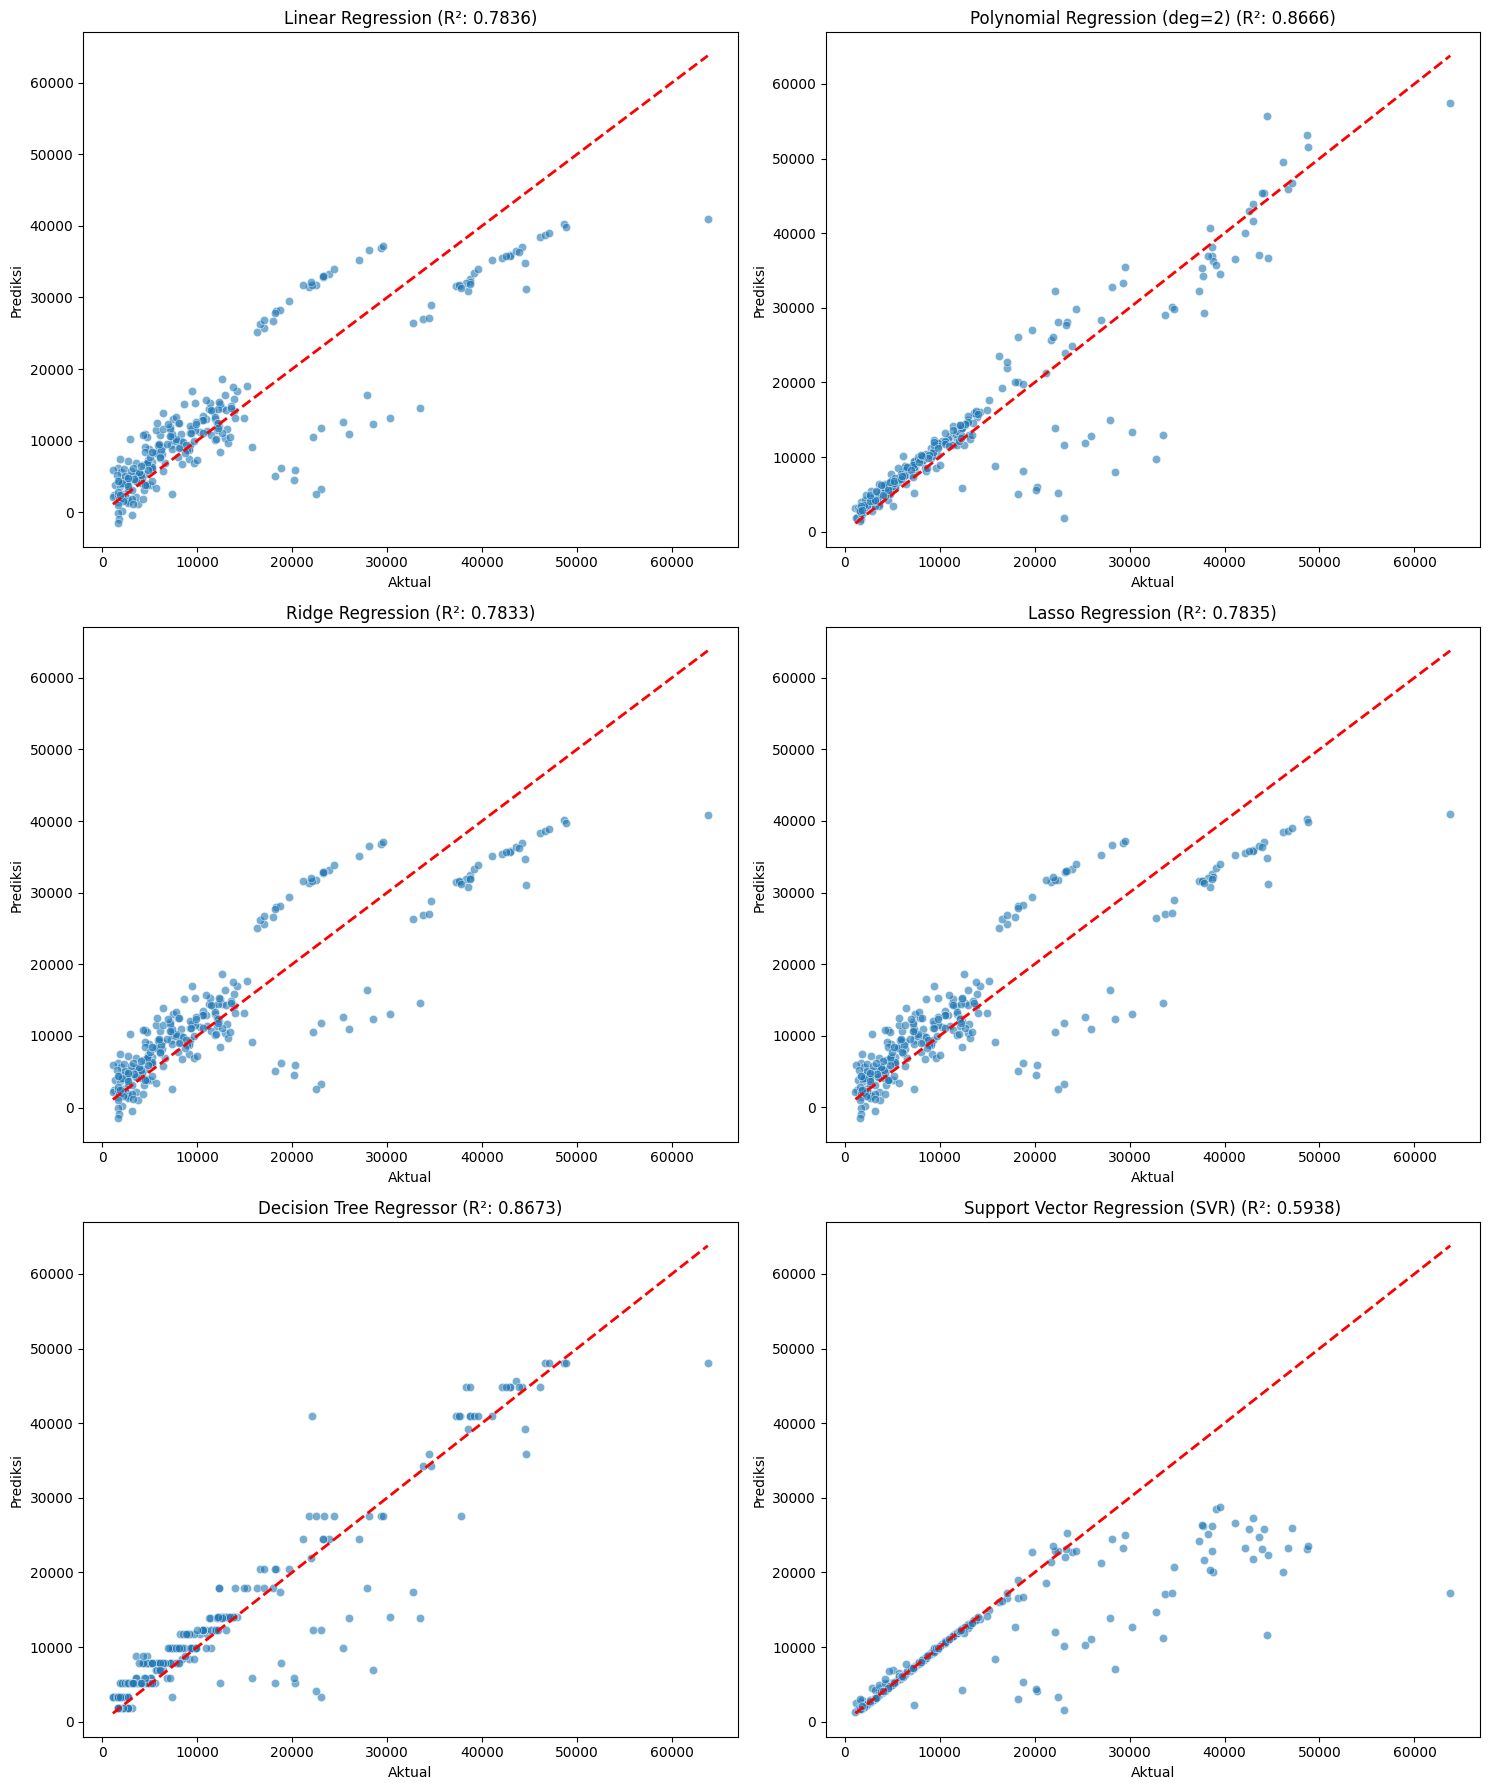

In [201]:
# Buat visualisasi perbandingan nilai aktual dan prediksi jika diperlukan.
fig, axes = plt.subplots(3, 2, figsize=(15, 18))
axes = axes.flatten()

for i, (model_name, y_pred) in enumerate(predictions.items()):
    sns.scatterplot(x=y_test, y=y_pred, ax=axes[i], alpha=0.6)
    axes[i].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    axes[i].set_title(f'{model_name} (R²: {r2_score(y_test, y_pred):.4f})')
    axes[i].set_xlabel('Aktual')
    axes[i].set_ylabel('Prediksi')

plt.tight_layout()
plt.show()

# 5. Analisis

#### Bandingkan hasil Linear Regression, Polynomial Regression, Ridge, Lasso, Decision Tree Regressor, dan SVR berdasarkan metrik evaluasi. Jelaskan pengaruh preprocessing dan parameter yang digunakan terhadap hasil.


Menurut hasil metrik evaluasi model terbaik adalah Decision Tree Regressor dari segala metrik dari MAE, MSE, RMSE, R^2. preprocessing yang dilakukan adalah StandardScaler dan OneHotEncoder, untuk StandardScaler sangat penting untuk model yang berbasis jarak agar suatu fitur yang nominal yang besar tidak mendominasi fitur yang lain namun untuk Decision tree tidak terlalu beperngaruh karena decision tree membandingkan fitur sendiri dengan hasil tidak dengan fitur lain.

 Untuk Polynomial Regression parameter degree = 2 yang semakin tinggi degree maka model dapat menangkap pola lebih kompleks dari fitur fitur di data namun jika terlalu besar maka overfit. Untuk Ridge dan Lasso regression parameter alpha digunakan sebagai kekuatan penalti, Ridge(L2) membatasi nilai koefisien agar tidak terlalu besar tapi tidak bisa nol, Lasso(L1) mengeliminasi fitur yang dianggap tidak penting dengan mengubah koefisien menjadi nol jika alpha besar maka model sederhana tapi jika terlalu kecil maka seperti linear regression. Untuk decision Tree parameter max_depth digunakan untuk membatasi tinggi pohon jika terlalu besar maka akan overfit karena terlalu melihat semua pola yang ada sebagai pola yang dapat dipelajari, sedangkan jika terlalu rendah maka tidak bisa mendapat pola sama sekali seperti asal. Untuk Support Vector Regression parameter C digunakan untuk menentukan batas toleransi kesalahan jika C terlalu besar maka model akan berusaha meminimalkan kesalahan pada training set secara ekstrem (rentan overfit), sedangkan jika C terlalu kecil, model akan lebih toleran terhadap kesalahan namun berisiko underfit.

# 6. Kesimpulan dan Saran

#### Berikan kesimpulan berdasarkan hasil eksperimen. Saran dapat berupa perubahan parameter, preprocessing, atau eksperimen lanjutan.


Kesimpulan:
- preprocess seperti StandardScaler sangat penting untuk model yang berbasis jarak
- parameter sangat penting untuk akurasi dan interpretasi hasil model

Saran:
- bisa melakukan feature engineering agar dapat melihat perbedaan lain dari tiap model